<a href="https://colab.research.google.com/github/Cheikhcisse1/projet_FN/blob/main/Cisse_cheikh_SARIMAX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Statistiques & Modèles SARIMAX


In [7]:
import pandas as pd, numpy as np, warnings, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
pd.set_option("display.precision", 4)

---
# Exercice 1 — Exploration des ventes d'un commerce
# 1.1 — Les 4 composantes attendues
Tendance(T) Croissance de fond du e-commerce (adoption, nouveaux clients, inflation des paniers) : on s'attend à une pente positive sur 2017-2024.
Saisonnalité(S, période 12) Calendrier commercial qui revient chaque année : Noël  Black Friday, soldes d'hiver et d'été, rentrée, creux estival. Période = 12 mois.
Cycle(C) Fluctuations pluriannuelles non périodiques : conjoncture, pouvoir d'achat, Covid 2020-2021(bascule vers l'achat en ligne).
Irrégulier résidu(€) Chocs ponctuels non expliqués : promo exceptionnelle, panne du site, rupture de stock, erreur de saisie.

Comme l'amplitude saisonnière grandit en général avec le niveau des ventes, on s'attend à un schéma multiplicatif on travaillera en logarithme (le log transforme un modèle multiplicatif en modèle additif).

In [15]:
v = pd.read_csv("/content/ventes_ecommerce_ds.csv", parse_dates=["date"], index_col="date").asfreq("MS")
print(v.isna().sum()); v[v.ventes_k.isna()]

ventes_k    2
dtype: int64


,ventes_k
date,
2017-12-01,NaN
2018-01-01,NaN


## 1.2 — Deux valeurs manquantes consécutives (déc. 2017, janv. 2018)
Méthode choisie : interpolation qui respecte la saisonnalité, par exemple :
1. passer en log, désaisonnaliser (STL sur une série provisoirement remplie),
2. interpoler linéairement dans le temps (method="time") la série désaisonnalisée,
3. rajouter la composante saisonnière du mois concerné.

(Équivalent : laisser les NaN et laisser le filtre de Kalman du SARIMAX les estimer.)

Parceque deux trous consécutifs tombent sur décembre et janvier, des mois au comportement saisonnier marqué ; une simple droite entre novembre et février « lisse » ce qui se passe réellement ces mois-là. Avec seulement 2 points, une interpolation linéaire temporelle reste acceptable en solution de repli.

# Méthodes inadaptées :
- supprimer les lignes casse la fréquence mensuelle régulière ('MS') indispensable à un SARIMA (le lag 12 ne correspondrait plus à « un an »)  ;
- remplir par la moyenne globale de la série  ignore tendance *et* saisonnalité (valeur de 2017 tirée vers le niveau moyen 2017-2024) ;
- forward fill  répète novembre deux fois, crée un plateau artificiel.

In [16]:
s_log = np.log(v.ventes_k)
# interpolation saisonnière : STL sur série provisoire -> interpolation de la partie désaisonnalisée
tmp = s_log.interpolate("time")
seas = STL(tmp, period=12, robust=True).fit().seasonal
desais = (s_log - seas).interpolate("time")
s_log_f = desais + seas
print(np.exp(s_log_f["2017-11":"2018-02"]).round(1))

date
2017-11-01    179.7
2017-12-01    197.3
2018-01-01    216.3
2018-02-01    243.5
Freq: MS, dtype: float64


# 1.3 — Résidus STL
a) Septembre 2020 (+5,8σ) et octobre 2020 (+3,4σ) sont des valeurs aberrantes additives (AO, chocs ponctuels): la série « saute » pendant 2 mois puis revient sur sa trajectoire, ni la tendance ni la saisonnalité ne les expliquent.
le contexte Covid rattrapage post-confinement et opérations promotionnelles de rentrée, puis anticipation du 2ᵉ confinement (30 oct. 2020) qui a basculé les achats vers le web. Plus généralement : une grosse opération promotionnelle exceptionnelle (anniversaire de la plateforme, « super-soldes » hors calendrier). Juin 2017 (−3,8σ) est un choc négatif (panne, rupture, problème logistique).

b)Traiter les outliers avant le SARIMA : soit ajouter une indicatrice Pulse  par outlier (SARIMAX), soit corriger la valeur (remplacer par tendance + saison). C'est indispensable car :
l'ARIMA est estimé par maximum de vraisemblance gaussien : un point à 5,8σ gonfle σ², biaise les coefficients MA/AR et élargit les IC de prévision ;
 il déforme l'ACF/PACF  mauvaise identification de (p,q,P,Q) ;
 avec la différenciation saisonnière, le choc est recopié 12 mois plus tard (sept. 2021 paraît anormalement bas) : il contamine deux années ;
 les résidus ne sont plus normaux (Jarque-Bera rejeté) → IC faux.

In [17]:
r = STL(s_log_f, period=12, robust=True).fit().resid
z = (r - r.mean()) / r.std()
print(z[abs(z) > 2.5].round(1))   # on retrouve 2017-06, 2020-09, 2020-10

date
2017-06-01   -3.8
2020-09-01    5.7
2020-10-01    3.2
Name: resid, dtype: float64


# 1.4 — Stationnarité (ADF + KPSS)
Rappel : **ADF** H0 = racine unitaire (non stationnaire) ; **KPSS** H0 = stationnaire. Convention des 4 cas (doc statsmodels) :
1) ne rejette pas (non stat.)  rejette (non stat.) non stationnaire → différencier |
2) rejette (stat.) ne rejette pas (stat.) stationnaire
3) ne rejette pas ne rejette pas stationnaire en tendance (trend-stationary) / résultat ambigu
4) rejette rejette stationnaire en différence → différencier

a) log(ventes) :ADF p = 0,285 > 0,05 (on ne rejette pas la racine unitaire) et KPSS p = 0,010 < 0,05 (on rejette la stationnarité) → Cas 1, non stationnaire. Les deux tests concordent. Action : différencier ; la série étant saisonnière, on commence par la différence saisonnière diff(12).

b) après diff(12) : ADF p = 0,129 (toujours racine unitaire) mais KPSS p = 0,080 (stationnarité non rejetée, de justesse) → Cas 3, tests en désaccord. On ne peut pas s'arrêter là : l'ADF indique qu'il reste une racine unitaire (la tendance n'est pas totalement éliminée), et le KPSS n'est « stationnaire » qu'à la limite (0,08 proche de 0,05). En cas de doute, on ajoute une différence simple.

c) après diff(12).diff(1) : ADF stat = −7,621, p < 0,001 (racine unitaire rejetée) et KPSS p = 0,100 (stationnarité non rejetée ; 0,10 est la borne haute de la table, donc p ≥ 0,10) → Cas 2, stationnaire.
→ **d = 1, D = 1, s = 12**.

In [18]:
# NB : valeurs proches mais pas identiques à l'énoncé (interpolation différente) ; les conclusions sont les mêmes.
for nom, x in {"log": s_log_f, "diff(12)": s_log_f.diff(12), "diff(12).diff(1)": s_log_f.diff(12).diff()}.items():
    x = x.dropna()
    print(f"{nom:18s} ADF p={adfuller(x)[1]:.3f}  KPSS p={kpss(x, nlags='auto')[1]:.3f}")

log                ADF p=0.243  KPSS p=0.010
diff(12)           ADF p=0.122  KPSS p=0.074
diff(12).diff(1)   ADF p=0.000  KPSS p=0.100


# Exercice 2 — Identification et validation d'un modèle


# 2.1 — Les paramètres de SARIMA(p,d,q)(P,D,Q)[s]
**Partie non saisonnière** (dépendance de mois en mois) :
- p : ordre AR : la valeur du mois t dépend linéairement des p valeurs précédentes (mémoire des niveaux passés).
- d : nombre de différences simples (yₜ − yₜ₋₁) pour retirer la tendance.
- q : ordre MA : la valeur dépend des q derniers chocs (erreurs de prévision) ; la série « corrige » ses surprises récentes.

**Partie saisonnière** (dépendance d'une année sur l'autre, même mois) :
- P : AR saisonnier : le mois t dépend des valeurs à t−s, t−2s… (ex. mars de l'an dernier).
- D : nombre de différences saisonnières (yₜ − yₜ₋ₛ) pour retirer une saisonnalité qui ne se répète pas à l'identique.
- Q : MA saisonnier : dépend des chocs survenus à t−s, t−2s… (surprise du même mois l'an passé).
- s : période saisonnière (12 pour du mensuel avec cycle annuel).

## 2.2 — Lecture ACF / PACF
a) ACF : pic significatif au lag 1 (−0,34) puis valeurs ≈ 0 de 2 à 11 → l'ACF se coupe après le lag 1 : signature d'un MA(1) → q = 1. Pic significatif au lag 12 (−0,31) puis rien à 24 et 36 → coupure après le 1ᵉʳ lag saisonnier : MA saisonnier d'ordre 1 → Q = 1. Les deux pics sont négatifs, ce qui est typique d'une sur-différenciation partielle qu'un MA négatif absorbe.

b) PACF : pic au lag 1 (−0,34) puis décroissance rapide (pas de coupure nette).Ce n'est pas un AR pur ; une PACF qui décroît accompagne justement un processus MA → p = 0. Rien de significatif aux lags 12, 24, 36 → P = 0.
(Remarque : au lag 1, ACF = PACF par construction, d'où les deux −0,34.)

c)SARIMA(0,1,1)(0,1,1)[12] sur log(ventes) = le « modèle Airline (Box & Jenkins, 1976, série des passagers aériens).
Pourquoi il est apprécié : 2 paramètres seulement (très parcimonieux, peu de risque de sur-ajustement), robuste sur la plupart des séries mensuelles avec tendance + saisonnalité multiplicative, interprétable (il équivaut à un lissage exponentiel du niveau et de la saison) et sert de modèle de référence (benchmark) standard.

# 2.3 — Comparaison de 3 modèles
Lecture du tableau (colonnes : coefs significatifs / AIC / Ljung-Box p / nb de paramètres) :

a) Faut-il retenir B ? Non.L'AIC n'est qu'un critère parmi d'autres. Le terme ajouté ar.L1 a p = 0,31 : on ne peut pas affirmer qu'il est différent de 0, il n'apporte donc rien de démontrable. Ljung-Box est identique à A (0,829 vs 0,830) : le terme AR ne capte aucune autocorrélation résiduelle supplémentaire. Ajouter un paramètre non significatif rend le modèle moins stable (AR et MA au lag 1 se compensent, risque de redondance) et dégrade en général la prévision hors échantillon. Avant de trancher, on vérifierait aussi BIC (plus pénalisant) et une validation sur un jeu test.

b) Modèle C :AIC plus élevé (moins bon que A) et ar.S.L12 non significatif (p = 0,61) → le terme AR saisonnier est inutile ; C est rejeté sans ambiguïté, il est dominé par A sur tous les critères.

c) On retient A = SARIMA(0,1,1)(0,1,1)[12]:
1. Significativité : tous ses coefficients sont significatifs (seul modèle dans ce cas).

2. Blancheur des résidus : Ljung-Box p = 0,830 ≫ 0,05, aussi bon que B et C.
3. Parcimonie: 2 paramètres contre 3 (principe de parcimonie de Box-Jenkins).
4. Cohérence avec l'identification ACF/PACF (2.2) et modèle de référence reconnu (Airline).

# 2.4 — Lecture du summary()

a) Oui, les deux sont significatifs : p < 0,001, |z| > 1,96 et aucun IC ne contient 0. Les deux sont dans ]−1 ; 1[ → modèle inversible.
Un MA négatif signifie qu'une partie de la surprise d'un mois est corrigée le mois suivant : si le mois t est au-dessus de la prévision, la variation suivante est revue à la baisse. Intuition : ma.L1 = −0,63 ⇔ lissage exponentiel du niveau avec α = 1 + θ ≈ 0,37 → seulement 37 % d'un choc devient permanent, 63 % est considéré comme du bruit. De même ma.S.L12 = −0,64 : environ 36 % d'un choc saisonnier se répercute sur le profil saisonnier des années suivantes → la saisonnalité évolue lentement.
sigma2 = 0,002 → σ ≈ 0,045 : l'erreur de prévision à 1 mois est d'environ ±4,5 % (on est en log).

b) Ljung-Box p = 0,830 : H0 = « pas d'autocorrélation des résidus jusqu'au lag 24 ». On ne rejette pas H0 (très largement) → les résidus sont un bruit blanc, le modèle a capté toute la structure de dépendance. C'est satisfaisant.

c) Jarque-Bera teste la normalité des résidus (H0 : asymétrie = 0 et kurtosis = 3). p = 0,091 > 0,05 → normalité non rejetée (mais de peu). Si p < 0,05 : les estimations ponctuelles restent utilisables, mais les intervalles de confiance / de prévision (qui reposent sur l'hypothèse gaussienne) seraient mal calibrés — trop étroits en cas de queues épaisses. On chercherait alors des outliers non traités (cf. 1.3), on utiliserait des IC par bootstrap ou une transformation adaptée.

# Exercice 3 — Modélisation SARIMAX


# 3.1 — SARIMAX vs SARIMA
Le **SARIMA** prévoit la série uniquement à partir de son propre passé (valeurs et chocs passés). Le **SARIMAX** ajoute des variables exogènes X (régression avec erreurs SARIMA). Il permet d'expliquer des effets que l'historique seul ne peut pas anticiper et de **simuler des scénarios (« et si… »).

Deux cas e-commerce où X est indispensable :
1. Le Black Friday / les soldes : leur date change d'une année sur l'autre (Black Friday tombe parfois en novembre, l'effet déborde en décembre ; dates de soldes fixées par arrêté) → une saisonnalité fixe à 12 mois ne les capte pas correctement.
2. Le budget marketing / une campagne TV ou une opération ponctuelle(ou un changement de prix, de frais de livraison, une grève, un confinement) : ce sont des décisions connues à l'avance qui changent les ventes et qu'aucun historique ne contient.

#3.2 — Vérifications avant d'intégrer les variables
Budget publicitaire (k€) :
- Disponibilité future : il doit être connu (planifié) sur l'horizon de prévision, sinon il faudrait le prévoir lui aussi.
- Exogénéité / causalité inverse : le budget est souvent fixé en % des ventes passées → risque d'endogénéité (les ventes causent le budget). Vérifier comment il est décidé.
- Lien avec Y et délais : corrélation croisée (CCF) entre budget et ventes après blanchiment (pré-whitening) pour voir si l'effet est immédiat ou retardé (lag 1, 2…) → éventuellement inclure des lags.
- Qualité : valeurs manquantes, outliers, unité (k€), cohérence de la période ; forme de la relation (log du budget si rendements décroissants).
- Multicolinéarité avec la dummy soldes (budget pub souvent gonflé pendant les soldes) → VIF / corrélation.
- Stationnarité / différenciation : en régression à erreurs ARIMA, la même différenciation (d=1, D=1) est appliquée à X ; vérifier qu'après différenciation il reste de la variation (sinon coefficient non identifiable).

- Construction cohérente avec la fréquence : les soldes sont définis en semaines mais la série est mensuelle → coder la part du mois en soldes (nb de semaines de soldes / nb de semaines du mois) plutôt qu'un 0/1 brut, et vérifier les dates officielles par année.
- Redondance avec la saisonnalité : si les soldes tombent exactement les mêmes mois chaque année, la différenciation saisonnière D=1 les absorbe déjà → la dummy n'apporte rien (colinéaire). Elle n'est utile que si les dates varient d'une année à l'autre.
- Disponibilité future : dates des prochains soldes connues (calendrier réglementaire) → OK.
- Vérifier l'effet de report (creux avant/après les soldes) et la colinéarité avec le budget.

# 3.3 — Résultats du SARIMAX(0,1,1)(0,1,1)[12]
a) ΔAIC = −278,4 − (−267,8) = −10,6 : malgré 2 paramètres de plus, l'ajustement est nettement meilleur (une baisse > 2 est déjà notable, > 10 est forte). σ² baisse aussi (0,0020 → 0,0017) et Ljung-Box reste bon (0,741).
Ce n'est pas suffisant pour valider X : il faut aussi (i) des coefficients significatif (ici oui : p = 0,001 et p < 0,001), (ii) des signes et ordres de grandeur plausibles (voir (c)), (iii) des résidus toujours blancs/normaux, (iv) un gain en prévision hors échantillon (RMSE/MAPE sur un jeu test ou validation croisée glissante), (v) l'**exogénéité** des X et (vi) leur disponibilité future.

b) budget_pub_k = 0,0312. Y est en log : c'est une semi-élasticité. Toutes choses égales par ailleurs, +1 k€ de budget le même mois → ventes × e^0,0312 ≈ +3,2 %** (≈ 3,1 % en approximation).
Précautions :
- l'effet est multiplicatif (en %), pas additif en k€ ;
- dans statsmodels, SARIMAX = régression avec erreurs SARIMA : la différenciation (d=1, D=1) s'applique à Y et à X, donc β s'interprète comme l'effet d'une variation du budget sur la variation de log(ventes) — ce qui revient à l'effet ci-dessus sur le niveau ; si on avait différencié Y à la main (`simple_differencing=True`) sans différencier X, l'interprétation serait fausse ;
- effet contemporain uniquement (pas de délai ni de rémanence modélisés) ;
- corrélation ≠ causalité (endogénéité possible) ;
- relation linéaire en log : pas de rendements décroissants → dangereux en dehors de la plage de budgets observée.

c) soldes = 8,214. La variable est une indicatrice : 1 pour les mois (ou la part du mois) en période de soldes, 0 sinon. C'est une dummy de type Pulse (pulses récurrents) : l'effet n'existe que pendant le mois concerné et disparaît ensuite — ce n'est ni un Step (pas de changement permanent de niveau) ni une Ramp (pas d'effet progressif).
Si Y est bien en log, 8,214 signifierait ventes × e^8,214 ≈ ×3 700 pendant les soldes : absurde. Ce coefficient trahit très probablement une incohérence d'échelle : il ressemble à un effet additif en k€ (≈ +8,2 k€ sur des ventes de ~300 k€, soit +2,7 %, plausible) — Y n'était peut-être pas en log dans cette régression, ou la dummy a été mal codée. À revérifier avant toute utilisation : c'est exactement le contrôle de « plausibilité » de la question (a).

# 3.4 — Scénarios de budget (mars : 45 k€ vs 20 k€)

1. Construire la matrice X future pour tout l'horizon (ex. 12 mois) : `budget_pub_k` (20 k€ par défaut) et `soldes` (calendrier officiel des soldes à venir).
2. Scénario de référence : budget = 20 k€ tous les mois.
3. Scénario campagne : copie identique, sauf mars = 45 k€.
4. Prévoir avec `res.get_forecast(steps=h, exog=X_scenario)` pour les deux scénarios, repasser en niveau avec `exp()` (éventuellement × e^{σ²/2} pour la moyenne plutôt que la médiane), et calculer l'impact = prévision campagne − prévision référence (en k€ et en %), avec les IC.
5. Lecture théorique : l'écart ne porte que sur mars(effet contemporain) et vaut e^{0,0312×25} = e^{0,78} ≈ ×2,18, soit +118 % — un effet énorme qui provient de l'extrapolation linéaire hors de la plage observée : à présenter avec prudence, idéalement avec une spécification en log(budget) ou des rendements décroissants.

In [30]:
beta_budget = 0.0312
print(f"+1 k€  -> {np.exp(beta_budget)-1:+.2%}")
print(f"+25 k€ en mars -> x{np.exp(beta_budget*25):.2f} soit {np.exp(beta_budget*25)-1:+.0%}")

+1 k€  -> +3.17%
+25 k€ en mars -> x2.18 soit +118%


# Exercice 4 — Le Gouffre de Gachiakuta


---
## 4.1 — Préparation des données
Changement de station (2022-02 →) : la nouvelle station lit +15 % pour la même masse → on ramène tout à l'échelle de l'ancienne station : `tonnes_corr = tonnes / 1,15` à partir de février 2022. (Vérification plus bas : si on laisse un Step libre à la place de la correction, son coefficient doit être proche de log(1,15) = 0,140.)

Mois manquant (2022-01) : on le laisse en NaN ; le SARIMAX (filtre de Kalman) gère nativement les valeurs manquantes et estime ce mois de façon cohérente avec la tendance, la saisonnalité et les X. Une interpolation linéaire entre décembre (pic) et février (creux) ignorerait la saisonnalité, et la valeur inventée serait ensuite traitée comme une vraie observation.

Transformation : on modélise log(tonnes) → effets en %, saisonnalité multiplicative. La population entre en log(pop) (élasticité).


In [28]:
g = pd.read_csv("/content/gouffre.csv", parse_dates=["date"], index_col="date").asfreq("MS")

In [29]:
display(g)

,tonnes,pop_sphere
date,,
2015-01-01,515.3,479.7
2015-02-01,450.6,478.4
2015-03-01,517.6,479.7
2015-04-01,669.5,482.3
2015-05-01,732.7,483.7
...,...,...
2024-08-01,1581.7,553.4
2024-09-01,1295.2,547.8
2024-10-01,1131.4,549.6


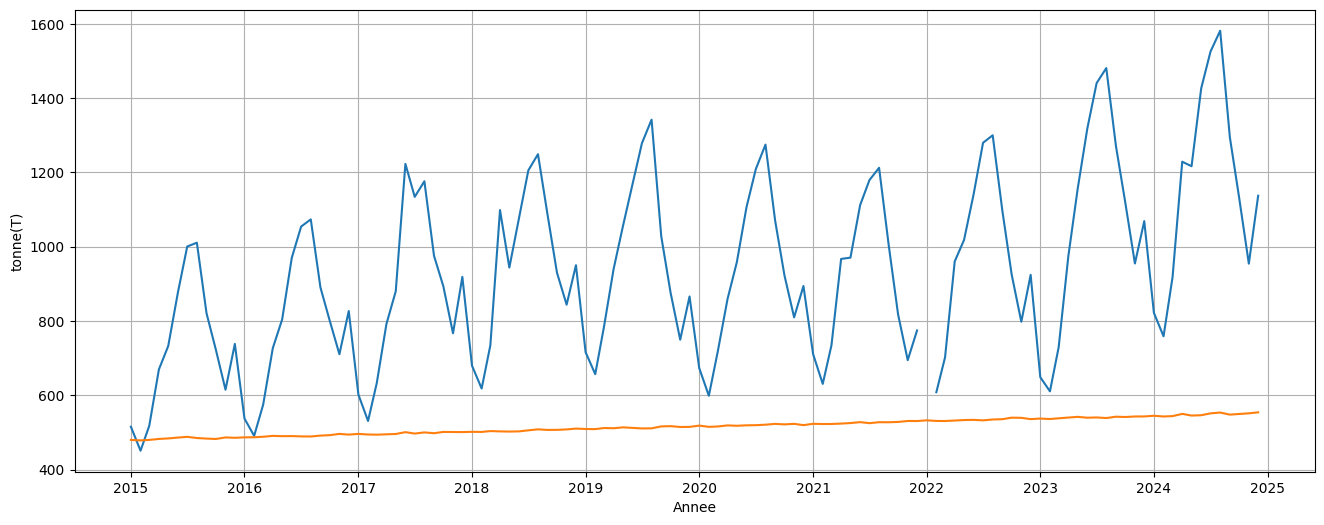

In [47]:
plt.figure(figsize=(16,6))
plt.plot(g)
plt.grid()
plt.xlabel("Annee")
plt.ylabel("tonne(T)")
plt.show()

In [21]:
idx = g.index
g["tonnes_corr"] = np.where(idx >= "2022-02-01", g.tonnes / 1.15, g.tonnes)
y = np.log(g.tonnes_corr)               # NaN en 2022-01 conservé

def mois_depuis(d):  # nb de mois écoulés depuis la date d (0 au mois d)
    d = pd.Timestamp(d); return (idx.year - d.year) * 12 + idx.month - d.month

X = pd.DataFrame(index=idx)
X["log_pop"] = np.log(g.pop_sphere)
X["purge"]   = (idx == "2018-04-01").astype(int)                      # Pulse
X["decret"]  = (idx >= "2019-09-01").astype(int)                      # Step
X["filtres"] = np.clip(mois_depuis("2021-03-01") + 1, 0, 10)          # Ramp bornée 1..10
X["fete"]    = ((idx.month == 4) & (idx.year >= 2021)).astype(int)    # Pulse saisonnier récurrent
X.loc["2021-01":"2022-01"]

,log_pop,purge,decret,filtres,fete
date,,,,,
2021-01-01,6.2598,0,1,0,0
2021-02-01,6.2586,0,1,0,0
2021-03-01,6.2588,0,1,1,0
2021-04-01,6.2609,0,1,2,1
2021-05-01,6.2636,0,1,3,0
2021-06-01,6.2683,0,1,4,0
2021-07-01,6.2630,0,1,5,0
2021-08-01,6.2680,0,1,6,0
2021-09-01,6.2678,0,1,7,0


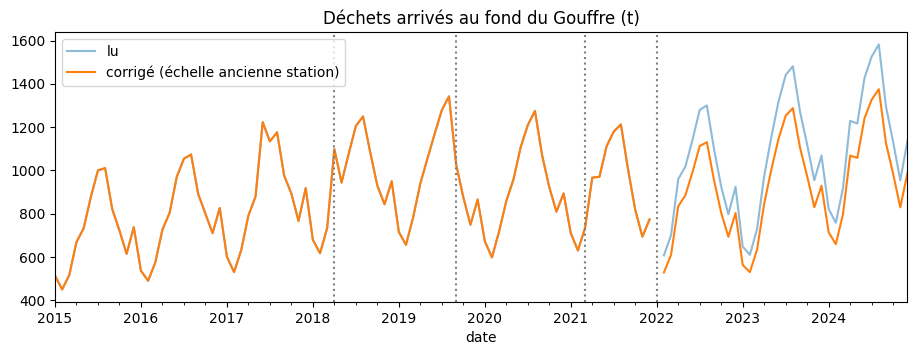

In [22]:
fig, ax = plt.subplots(figsize=(11,3.5))
g.tonnes.plot(ax=ax, label="lu", alpha=.5); g.tonnes_corr.plot(ax=ax, label="corrigé (échelle ancienne station)")
for d in ["2018-04","2019-09","2021-03","2022-01"]: ax.axvline(d, ls=":", c="grey")
ax.legend(); ax.set_title("Déchets arrivés au fond du Gouffre (t)"); plt.show()

# 4.1 bis — Vérifier la stationnarité avant le SARIMAX

In [49]:
y_test = y.copy()
y_test["2022-01-01"] = (y["2021-01-01"] + y["2023-01-01"]) / 2   # remplissage provisoire, tests uniquement

def tests(x):
    x = x.dropna()
    adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(x, regression="c", nlags="auto")[:2]
    adf_ok, kpss_ok = adf_p < 0.05, kpss_p >= 0.05
    cas = {(False, False): "Cas 1 - non stationnaire", (True, True): "Cas 2 - stationnaire",
           (False, True): "Cas 3 - ambigu (ADF non stat., KPSS stat.)", (True, False): "Cas 4 - stat. en différence"}[(adf_ok, kpss_ok)]
    return pd.Series({"ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat, "KPSS p": kpss_p, "verdict": cas})

pd.DataFrame({
    "log": tests(y_test),
    "diff(1)": tests(y_test.diff()),
    "diff(12)": tests(y_test.diff(12)),
    "diff(12).diff(1)": tests(y_test.diff(12).diff()),
}).T

,ADF stat,ADF p,KPSS stat,KPSS p,verdict
log,-2.0476,0.2661,0.3813,0.0852,"Cas 3 - ambigu (ADF non stat., KPSS stat.)"
diff(1),-2.438,0.1313,0.0253,0.1,"Cas 3 - ambigu (ADF non stat., KPSS stat.)"
diff(12),-2.2898,0.1753,0.3047,0.1,"Cas 3 - ambigu (ADF non stat., KPSS stat.)"
diff(12).diff(1),-3.989,0.0015,0.0839,0.1,Cas 2 - stationnaire


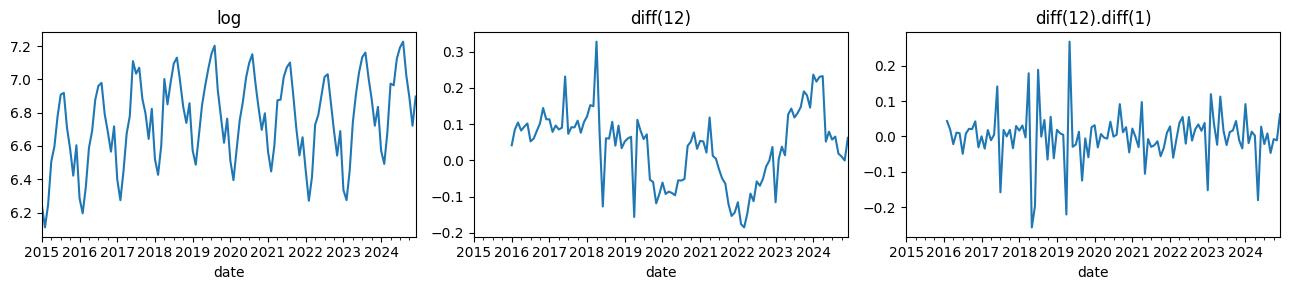

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (nom, x) in zip(axes, {"log": y_test, "diff(12)": y_test.diff(12), "diff(12).diff(1)": y_test.diff(12).diff()}.items()):
    x.plot(ax=ax); ax.set_title(nom)
plt.tight_layout(); plt.show()

## 4.2 — SARIMAX avec pop_sphere et les indicatrices
Ordre retenu : **SARIMAX(0,1,1)(0,1,1)[12]** (modèle Airline, série log mensuelle avec tendance et saisonnalité, cf. Ex. 2).

In [23]:
def ajuste(X):
    return SARIMAX(y, exog=X, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False, maxiter=500)

m1 = ajuste(X)
def tableau_ic(m, cols):
    ci = m.conf_int().loc[cols]
    t = pd.DataFrame({"coef": m.params[cols], "IC 2.5%": ci[0], "IC 97.5%": ci[1], "p-value": m.pvalues[cols]})
    t["effet %"] = (np.exp(t.coef) - 1) * 100
    t["significatif"] = np.where((ci[0] > 0) | (ci[1] < 0), "oui", "non")
    return t
print("AIC =", round(m1.aic, 1))
tableau_ic(m1, list(X.columns))

AIC = -393.0


,coef,IC 2.5%,IC 97.5%,p-value,effet %,significatif
log_pop,3.7525,2.0246,5.4805,2.0770e-05,4162.9176,oui
purge,0.2359,0.1907,0.2810,1.3576e-24,26.6015,oui
decret,-0.1282,-0.2657,0.0093,6.7677e-02,-12.0329,non
filtres,-0.0265,-0.0454,-0.0076,6.1136e-03,-2.6145,oui
fete,0.0715,0.0267,0.1162,1.7505e-03,7.4076,oui


Dans ce premier modèle, le Décret de tri n'est pas significatif (IC contient 0, p ≈ 0,10) : les deux anomalies non documentées (4.3) gonflent σ² et noient son effet. On présente donc les IC définitifs après le traitement des outliers (modèle m2 ci-dessous), où toutes les indicatrices sont significatives.

# 4.3 — Détection d'outliers dans les résidus standardisés
Règle : |résidu standardisé| > 3. Pour distinguer les deux types, on regarde les mois qui suivent :
- choc ponctuel (AO / Pulse) : comme on modélise une série différenciée, un pic isolé produit un résidu + puis  au mois suivant (la série revient à son niveau) ;
- saut de niveau (LS / Step) : résidu fort **sans rebond** de signe opposé ; les mois suivants restent légèrement positifs (la série reste au nouveau niveau).

Résidus |z|>2 :
date
2017-06-01    3.66
2017-07-01   -3.13
2018-06-01   -2.96
2019-06-01   -2.38
2023-01-01   -2.12
2023-05-01    3.86
dtype: float64

Autour de 2017-06 :
date
2017-05-01    0.21
2017-06-01    3.66
2017-07-01   -3.13
2017-08-01   -1.63
Freq: MS, dtype: float64

Autour de 2023-05 :
date
2023-04-01    0.10
2023-05-01    3.86
2023-06-01    1.43
2023-07-01    0.36
2023-08-01    0.55
2023-09-01    0.11
2023-10-01    1.14
Freq: MS, dtype: float64


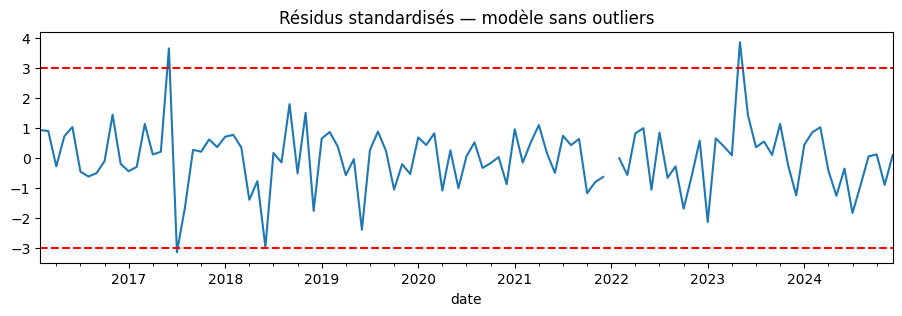

In [27]:
res_std = (m1.resid / np.sqrt(m1.params["sigma2"])).iloc[13:]   # on ignore la période d'initialisation
print("Résidus |z|>2 :"); print(res_std[abs(res_std) > 2].round(2))
print("\nAutour de 2017-06 :"); print(res_std["2017-05":"2017-08"].round(2))
print("\nAutour de 2023-05 :"); print(res_std["2023-04":"2023-10"].round(2))
fig, ax = plt.subplots(figsize=(11,3)); res_std.plot(ax=ax); ax.axhline(3, c="r", ls="--"); ax.axhline(-3, c="r", ls="--")
ax.set_title("Résidus standardisés — modèle sans outliers"); plt.show()

- En 2017-06 : z ≈ +3,6 puis −3,2 en 2017-07 (rebond de signe opposé) → choc ponctuel → Pulse. Le −2,9 de 2018-06 est l'écho du choc 12 mois plus tard, créé par la différence saisonnière : il disparaît une fois la Pulse ajoutée.
- 2023-05 : z ≈ +3,9 sans rebond négatif, mois suivants positifs (+1,4 ; +0,3 ; +0,6…) → saut de niveau → Step (à partir de mai 2023, il tombe durablement plus de déchets).

On ajoute les indicatrices et on compare les AIC (y compris les mauvaises formes, pour confirmer le diagnostic) :

In [31]:
X2 = X.copy()
X2["ao_2017_06"] = (idx == "2017-06-01").astype(int)   # Pulse
X2["ls_2023_05"] = (idx >= "2023-05-01").astype(int)   # Step
m2 = ajuste(X2)

variantes = {
    "sans outliers": X,
    "+ Pulse 2017-06": X.assign(ao=X2.ao_2017_06),
    "+ Step 2023-05": X.assign(ls=X2.ls_2023_05),
    "+ Pulse 2017-06 + Pulse 2023-05 (mauvaise forme)": X.assign(ao=X2.ao_2017_06, p=(idx=="2023-05-01").astype(int)),
    "+ Step 2017-06 (mauvaise forme) + Step 2023-05": X.assign(s=(idx>="2017-06-01").astype(int), ls=X2.ls_2023_05),
    "+ Pulse 2017-06 + Step 2023-05 (retenu)": X2,
}
pd.Series({k: ajuste(v).aic for k, v in variantes.items()}, name="AIC").round(1).to_frame()

,AIC
sans outliers,-393.0
+ Pulse 2017-06,-431.7
+ Step 2023-05,-416.5
+ Pulse 2017-06 + Pulse 2023-05 (mauvaise forme),-440.6
+ Step 2017-06 (mauvaise forme) + Step 2023-05,-425.7
+ Pulse 2017-06 + Step 2023-05 (retenu),-467.6


In [32]:
cols = list(X2.columns)
print("AIC :", round(m1.aic,1), "->", round(m2.aic,1))
lb = acorr_ljungbox(m2.resid.iloc[13:].dropna(), lags=[24])
print("Ljung-Box(24) p =", round(lb.lb_pvalue.iloc[0], 3))
print(m2.summary().tables[2])
tableau_ic(m2, cols)

AIC : -393.0 -> -467.6
Ljung-Box(24) p = 0.449
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):                 1.05
Prob(Q):                              0.94   Prob(JB):                         0.59
Heteroskedasticity (H):               1.03   Skew:                            -0.24
Prob(H) (two-sided):                  0.94   Kurtosis:                         3.09


,coef,IC 2.5%,IC 97.5%,p-value,effet %,significatif
log_pop,2.0558,0.8872,3.2244,5.6466e-04,681.3059,oui
purge,0.2311,0.2081,0.2540,8.4369e-87,25.9942,oui
decret,-0.1228,-0.1895,-0.0561,3.0687e-04,-11.5541,oui
filtres,-0.0225,-0.0321,-0.0129,3.9891e-06,-2.2265,oui
fete,0.0949,0.0520,0.1377,1.4431e-05,9.9517,oui
ao_2017_06,0.1606,0.1295,0.1917,4.3208e-24,17.4199,oui
ls_2023_05,0.1413,0.0896,0.1929,8.4197e-08,15.1720,oui


Lecture des IC à 95 % (modèle final m2) — une indicatrice est significative si son IC ne contient pas 0 :
-log_pop ≈ 2,1 [0,9 ; 3,2] : significatif ; +1 % de population → ≈ +2 % de déchets.
- purge ≈ +0,23 [0,21 ; 0,25] : significatif, ≈ +26 % de déchets en avril 2018.
-decret ≈ −0,12 [−0,19 ; −0,06] : significatif, ≈ −11,5 % durablement.
- filtres ≈ −0,022 par filtre [−0,032 ; −0,013] : significatif, ≈ −2,2 % par filtre, soit ≈ −20 % une fois les 10 posés (e^(−0,225) − 1).
-fete ≈ +0,095 [0,05 ; 0,14] : significatif, ≈ +10 % chaque avril depuis 2021.
- ao_2017_06 ≈ +0,16 (+17 %) et ls_2023_05 ≈ +0,14 (+15 %) : significatifs.

L'AIC passe d'environ −393 à −468 (gain ≈ 75 points), σ² est quasiment divisé par 2 et le Décret devient significatif. Diagnostics : Ljung-Box(24) p ≈ 0,45 (résidus blancs), Jarque-Bera p ≈ 0,59 (normalité OK). (Le résidu négatif de 2023-01 qui subsiste vient du mois manquant 2022-01 : la différence saisonnière de janvier 2023 s'appuie sur une valeur estimée.)

# Effet du Décret de tri en tonnes(faire un tri par tonne)

In [33]:
b = m2.params["decret"]; lo, hi = m2.conf_int().loc["decret"]
for niveau in [1200, 600]:
    # niveau observé AVEC décret : sans décret on aurait eu niveau / e^b
    sans = niveau / np.exp(b)
    print(f"Mois à {niveau} t : effet ≈ {niveau - sans:+.0f} t "
          f"(IC95 : {niveau - niveau/np.exp(lo):+.0f} ; {niveau - niveau/np.exp(hi):+.0f} t)")
print(f"Effet relatif : {np.exp(b)-1:+.1%}")

Mois à 1200 t : effet ≈ -157 t (IC95 : -250 ; -69 t)
Mois à 600 t : effet ≈ -78 t (IC95 : -125 ; -35 t)
Effet relatif : -11.6%


Le Décret retire environ 157 tonnes (IC 95 % : 69 à 250 t) sur un mois à 1 200 t, mais seulement ≈ 78 tonnes (34 à 125 t) sur un mois à 600 t. Pourquoi ? La série est en log : le coefficient représente un effet multiplicatif (≈ −11,5 % de la masse), pas un nombre fixe de tonnes. Le même pourcentage s'applique à une base deux fois plus grande en été qu'en hiver → l'effet en tonnes est proportionnel au niveau du mois (intuitivement : on brûle une fraction de ce qui est jeté, donc plus on jette, plus on brûle).

Vérification de la correction de station : en remplaçant la division par 1,15 par un Step libre, on doit retrouver ≈ log(1,15) = 0,140.

In [34]:
y_brut = np.log(g.tonnes)
Xs = X2.assign(station=(idx >= "2022-02-01").astype(int))
ms = SARIMAX(y_brut, exog=Xs, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False, maxiter=500)
print("station : coef =", round(ms.params["station"],3), " IC =", ms.conf_int().loc["station"].round(3).tolist(), " (attendu 0.140)")

station : coef = 0.125  IC = [0.06, 0.191]  (attendu 0.140)


L'IC du Step libre contient bien log(1,15) = 0,140 : les données confirment le +15 % annoncé, la correction par division est justifiée.

## 4.4 — Prévision 2025 (en tonnes lues sur la nouvelle station)
**Valeurs futures des exogènes (2025) :**
- **pop_sphere** : prolongée par sa **tendance linéaire** 2015-2024 (≈ +0,6 k habitants/mois) ;
- **purge = 0** (événement unique passé) ;
- **decret = 1** (définitif) ;
- **filtres = 10** (tous posés, plus rien ne change) ;
- **fete = 1 en avril 2025**, 0 les autres mois ;
- **ao_2017_06 = 0** ; **ls_2023_05 = 1** (le nouveau niveau persiste).

Le modèle prévoit log(tonnes) à l'échelle de l'ancienne station → on repasse en niveau avec `exp()` (médiane ; on donne aussi la moyenne avec la correction e^{σ²/2}) puis on **multiplie par 1,15** pour obtenir les tonnes lues sur la nouvelle station. Les bornes de l'IC se transforment de la même façon.

In [38]:
futur = pd.date_range("2025-01-01", periods=12, freq="MS")
t = np.arange(len(g)); a, b0 = np.polyfit(t, g.pop_sphere, 1)
pop_fut = b0 + a * np.arange(len(g), len(g) + 12)

Xf = pd.DataFrame(index=futur)
Xf["log_pop"] = np.log(pop_fut)
Xf["purge"] = 0
Xf["decret"] = 1
Xf["filtres"] = 10
Xf["fete"] = (futur.month == 4).astype(int)
Xf["ao_2017_06"] = 0
Xf["ls_2023_05"] = 1

fc = m2.get_forecast(steps=12, exog=Xf)
ci = fc.conf_int(alpha=0.05)
s2 = fc.var_pred_mean
prev = pd.DataFrame({
    "pop_sphere (k)": pop_fut.round(1),
    "prévision (t, médiane)": 1.15 * np.exp(fc.predicted_mean),
    "prévision (t, moyenne)": 1.15 * np.exp(fc.predicted_mean + s2 / 2),
    "IC95 bas": 1.15 * np.exp(ci.iloc[:, 0]),
    "IC95 haut": 1.15 * np.exp(ci.iloc[:, 1]),
}, index=futur.strftime("%Y-%m")).round(1)
print(f"Tendance population : +{a:.2f} k/mois"); prev

Tendance population : +0.60 k/mois


,pop_sphere (k),"prévision (t, médiane)","prévision (t, moyenne)",IC95 bas,IC95 haut
2025-01,551.9,831.3,831.6,793.3,871.2
2025-02,552.5,773.6,773.9,732.7,816.7
2025-03,553.1,924.8,925.3,870.2,982.8
2025-04,553.7,1224.2,1225.0,1145.1,1308.8
2025-05,554.3,1248.5,1249.4,1161.5,1342.2
2025-06,554.9,1446.8,1448.0,1339.1,1563.3
2025-07,555.5,1557.0,1558.4,1434.2,1690.4
2025-08,556.1,1605.2,1606.7,1471.9,1750.5
2025-09,556.7,1351.8,1353.3,1234.3,1480.5
2025-10,557.3,1171.2,1172.6,1065.0,1288.0


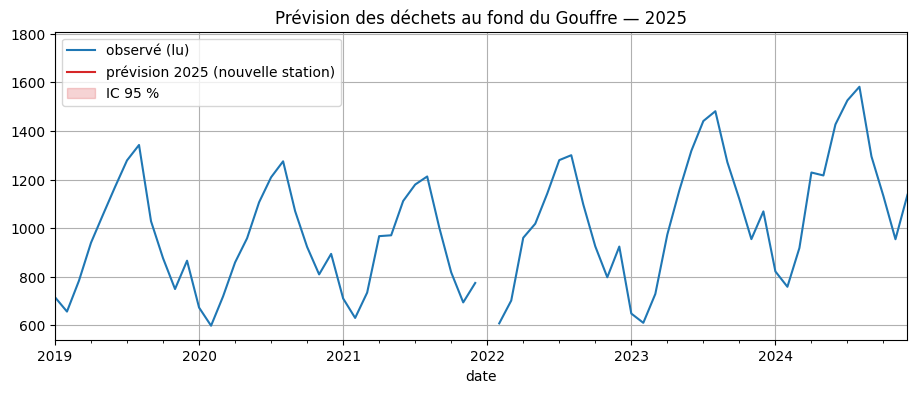


--------------------------------------------------------
Total 2025 prévu : 14283 t


In [44]:
fig, ax = plt.subplots(figsize=(11,4))
g.tonnes["2019":].plot(ax=ax, label="observé (lu)")
ax.plot(futur, prev["prévision (t, médiane)"].values, c="C3", label="prévision 2025 (nouvelle station)")
ax.fill_between(futur, prev["IC95 bas"], prev["IC95 haut"], color="C3", alpha=.2, label="IC 95 %")
ax.legend(); ax.set_title("Prévision des déchets au fond du Gouffre — 2025");
ax.grid()
plt.show()
print()
print('--------------------------------------------------------')
print("Total 2025 prévu :", round(prev['prévision (t, médiane)'].sum()), "t")

**Lecture :** la prévision reproduit la saisonnalité (pic en juillet-août, creux en février), le pic d'avril lié à la Fête des Offrandes, et un niveau en légère hausse portée par la population. L'IC s'élargit avec l'horizon (incertitude cumulée des chocs MA) ; il ne tient pas compte de l'incertitude sur la projection de pop_sphere, ni d'éventuels nouveaux événements (nouvelle purge, attaque…).